### Comparação de classificadores na CTG

Este notebook escolhe os hiperparâmetros de quatro classificadores da statstech (regressão logística, LDA, QDA e KNN) por validação cruzada e compara-os. 


#### 0. Configuração inicial 

In [43]:
import json
import time
import warnings

import matplotlib.pyplot as plt
import numpy as np
from statstech.discriminant_analysis import (
    LinearDiscriminantAnalysis,
    QuadraticDiscriminantAnalysis,
)
from statstech.linear_model import LogisticRegression
from statstech.model_selection import (
    GridSearchCV,
    StratifiedKFold,
    cross_val_predict,
    cross_val_score,
    LeaveOneOut,
    KFold
)
from statstech.neighbors import KNeighborsClassifier
from statstech.pipeline import Pipeline
from statstech.preprocessing import StandardScaler

from analysis.config import PROCESSED, SEED, STYLE, TABLES
from analysis.evaluation import evaluate_classifier
from analysis.io import load_dataset
from analysis.report import plot_search, save_figure, save_table
from analysis.validation import StratifiedGroupKFold
from analysis.threshold import THRESHOLDS, choose_threshold, predict_with_threshold, threshold_curve

plt.style.use(STYLE)

warnings.filterwarnings("ignore", message=".*indefinid.*")

CLASS_NAMES = ["normal", "suspeito", "patológico"]
PATHOLOGICAL = 2

#### 1. Dados e grupos do treino

ctg.npz traz treino e teste já separados por registro. Para a validação cruzada também precisamos saber de qual registro veio cada dado do treino.

In [3]:
data = load_dataset("ctg")
X_train, y_train = data["X_train"], data["y_train"]
feature_names = data["feature_names"].tolist()

groups_train = np.load(PROCESSED / "ctg_groups_train.npy")
assert len(groups_train) == len(y_train)

print(f"treino: {X_train.shape[0]} exames, {X_train.shape[1]} medidas, "
      f"{len(np.unique(groups_train))} registros")
for k, name in enumerate(CLASS_NAMES):
    n = np.sum(y_train == k)
    print(f"  {name:11s} {n:5d}  ({n / len(y_train):.1%})")

treino: 1755 exames, 20 medidas, 282 registros
  normal       1363  (77.7%)
  suspeito      245  (14.0%)
  patológico    147  (8.4%)


#### 2. Validação cruzada por registro

Segmentos do mesmo registro são muito parecidos. Se um cai no treino de um fold e outro na validação, o modelo "reconhece" o vizinho e o F1 sobe sem o modelo ter aprendido nada que generalize. 


In [4]:
cv = StratifiedGroupKFold(groups_train, n_splits=10, random_state=SEED)

##### 2.1 KNN com folds por linha e por registro 

Busca por k com duas validações diferentes, mas com fold por linha segmentos "irmãos" se misturam entre treino e validação.

In [5]:
def make_pipeline(model):
    return Pipeline([("scaler", StandardScaler()), ("model", model)])

ks = [1, 5, 15, 31, 61]
cv_by_row = StratifiedKFold(10, shuffle=True, random_state=SEED)
for label, splitter in [("folds por linha", cv_by_row), ("folds por registro", cv)]:
    search = GridSearchCV(make_pipeline(KNeighborsClassifier()), {"model__n_neighbors": ks},
                          cv=splitter, scoring="f1_macro").fit(X_train, y_train)
    print(f"{label:19s} melhor k = {search.best_params_['model__n_neighbors']:2d}   "
          f"F1 por k: {[round(r['mean_score'], 3) for r in search.cv_results_]}")

folds por linha     melhor k =  1   F1 por k: [0.834, 0.804, 0.786, 0.762, 0.722]
folds por registro  melhor k = 15   F1 por k: [0.694, 0.722, 0.723, 0.704, 0.663]


#### 3. Classificador baseline

Prever sempre a classe majoritária.

In [6]:
majority_class = np.bincount(y_train).argmax()
baseline = evaluate_classifier(y_train, np.full_like(y_train, majority_class))
print(f"acurácia {baseline['accuracy']:.3f} F1 macro {baseline['f1_macro']:.3f} "
      f"recall patológico {baseline['recall_2']:.3f}")

acurácia 0.777 F1 macro 0.291 recall patológico 0.000


#### 4. Busca de hiperparâmetros (F1 macro)

-> F1 macro: média do F1 das três classes.



In [7]:
grids = {
    "logistic": {"model__alpha": [0.01, 0.1, 1, 10]},
    "lda": {"model__reg_param": [1e-6, 1e-3, 1e-1]},
    "qda": {"model__reg_param": [1e-4, 1e-2, 0.1, 0.3, 0.5]},
    "knn": {"model__n_neighbors": [1, 5, 15, 31, 61]},
}
searches = {}


def show_search(search):
    # Uma linha por valor da grade, com a média ± desvio entre folds.
    results = search.cv_results_
    for i, r in enumerate(results):
        value = next(iter(r["params"].values()))
        mark = "  <- melhor" if i == search.best_index_ else ""
        print(f"  {value!s:>8}   {r['mean_score']:.3f} ± {r['std_score']:.3f}{mark}")
    #Quando o melhor valor é o primeiro ou o último da grade
    if search.best_index_ in (0, len(results) - 1):
        print("o melhor valor está na borda da grade.")

##### 4.1 Regressão Logística 

In [8]:
searches["logistic"] = GridSearchCV(
    make_pipeline(LogisticRegression()), grids["logistic"], cv=cv, scoring="f1_macro"
).fit(X_train, y_train)
show_search(searches["logistic"])

      0.01   0.786 ± 0.088  <- melhor
       0.1   0.786 ± 0.088
         1   0.781 ± 0.086
        10   0.776 ± 0.097
o melhor valor está na borda da grade.


Obs.: Como o melhor valor está na borda, talvez o modelo não tenha terminado de treinar. Vamos conferir inicialmente a convergência.

In [9]:
logistic = searches["logistic"].best_estimator_.named_steps_["model"]
loss = np.asarray(logistic.loss_history_)
print(f"iterações: {len(loss)} de max_iter = {logistic.max_iter}")
print(f"queda da perda nas últimas 100 iterações: {loss[-101] - loss[-1]:.4f}")

iterações: 1000 de max_iter = 1000
queda da perda nas últimas 100 iterações: 0.0022


A perda ainda estava caindo no final -> provavelmente não convergiu. 
Ideia: mais iterações ou passos maiores. 

In [10]:
alpha = searches["logistic"].best_params_["model__alpha"]
curves = {}
print("learning_rate  iterações  perda final  convergiu  perda sempre caindo")
for lr in [0.1, 0.5, 1.0, 2.0, 5.0]:
    model = make_pipeline(LogisticRegression(alpha=alpha, learning_rate=lr, max_iter=5000))
    history = np.asarray(model.fit(X_train, y_train).named_steps_["model"].loss_history_)
    curves[lr] = history
    print(f"{lr:13g}  {len(history):9d}  {history[-1]:11.4f}  {len(history) < 5000!s:>9}  "
          f"{bool(np.all(np.diff(history) <= 0))!s:>19}")

learning_rate  iterações  perda final  convergiu  perda sempre caindo
          0.1       5000       0.2119      False                 True
          0.5       2852       0.2065       True                 True
            1       1868       0.2059       True                 True
            2       1193       0.2055       True                 True
            5       5000       0.4073      False                False


Learning_rate = 1.0 é uma boa decisão entre os valores que convergem com a perda caindo. (Passos grandes são seguros pois as medidas estão padronizadas)

-> Nova busca, com o novo passo: 

In [11]:
searches["logistic"] = GridSearchCV(
    make_pipeline(LogisticRegression(learning_rate=1.0, max_iter=5000)),
    grids["logistic"], cv=cv, scoring="f1_macro",
).fit(X_train, y_train)
show_search(searches["logistic"])

      0.01   0.774 ± 0.083
       0.1   0.769 ± 0.096
         1   0.772 ± 0.095
        10   0.780 ± 0.099  <- melhor
o melhor valor está na borda da grade.


Agora o melhor `alpha` é o 10 (último da grade). Vamos estender o grid para ver se o F1 macro continua aumentando:

In [12]:
grids["logistic"] = {"model__alpha": [0.01, 0.1, 1, 10, 20, 100]}
searches["logistic"] = GridSearchCV(
    make_pipeline(LogisticRegression(learning_rate=1.0, max_iter=5000)),
    grids["logistic"], cv=cv, scoring="f1_macro",
).fit(X_train, y_train)
show_search(searches["logistic"])

      0.01   0.774 ± 0.083
       0.1   0.769 ± 0.096
         1   0.772 ± 0.095
        10   0.780 ± 0.099  <- melhor
        20   0.774 ± 0.092
       100   0.723 ± 0.074


##### 4.2 LDA

In [13]:
searches["lda"] = GridSearchCV(
    make_pipeline(LinearDiscriminantAnalysis()), grids["lda"], cv=cv, scoring="f1_macro"
).fit(X_train, y_train)
show_search(searches["lda"])

     1e-06   0.715 ± 0.092  <- melhor
     0.001   0.712 ± 0.090
       0.1   0.708 ± 0.085
o melhor valor está na borda da grade.


Obs.: o valor está na borda, mas os três F1 macro são quase iguais e um valor abaixo de 1e-6 praticamente não regulariza nada.

##### 4.3 QDA

In [14]:
searches["qda"] = GridSearchCV(
    make_pipeline(QuadraticDiscriminantAnalysis()), grids["qda"], cv=cv, scoring="f1_macro"
).fit(X_train, y_train)
show_search(searches["qda"])

    0.0001   0.670 ± 0.133
      0.01   0.689 ± 0.126
       0.1   0.694 ± 0.119
       0.3   0.713 ± 0.117
       0.5   0.733 ± 0.118  <- melhor
o melhor valor está na borda da grade.


Vamos estender a grade para observar se de fato 0.5 é o melhor: 

In [15]:
grids["qda"] = {"model__reg_param": [1e-4, 1e-2, 0.1, 0.3, 0.5, 0.7, 0.9]}
searches["qda"] = GridSearchCV(
    make_pipeline(QuadraticDiscriminantAnalysis()), grids["qda"], cv=cv, scoring="f1_macro"
).fit(X_train, y_train)
show_search(searches["qda"])

    0.0001   0.670 ± 0.133
      0.01   0.689 ± 0.126
       0.1   0.694 ± 0.119
       0.3   0.713 ± 0.117
       0.5   0.733 ± 0.118  <- melhor
       0.7   0.732 ± 0.109
       0.9   0.730 ± 0.109


De 0.5 a 0.9 o F1 macro fica estável, então `reg_param = 0.5` é suficiente.

##### 4.4 KNN

In [16]:
searches["knn"] = GridSearchCV(
    make_pipeline(KNeighborsClassifier()), grids["knn"], cv=cv, scoring="f1_macro"
).fit(X_train, y_train)
show_search(searches["knn"])

         1   0.694 ± 0.102
         5   0.722 ± 0.097
        15   0.723 ± 0.067  <- melhor
        31   0.704 ± 0.075
        61   0.663 ± 0.097


##### 4.5 F1 macro x hiperparâmetro

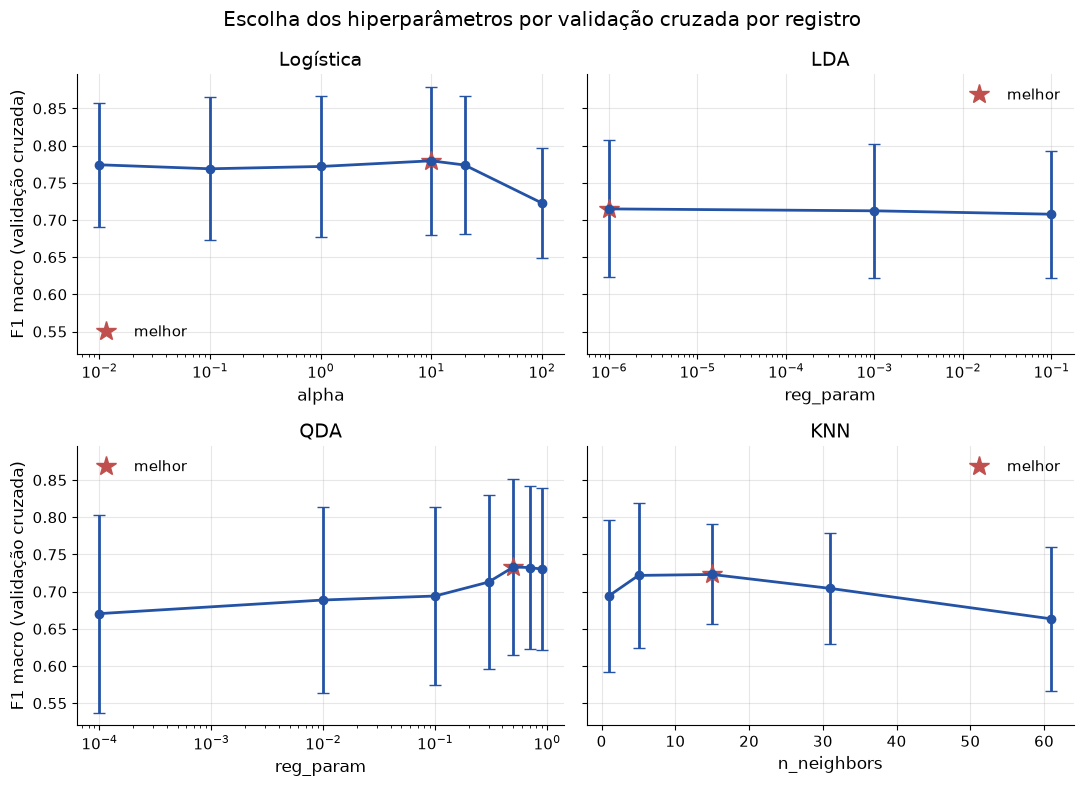

In [17]:
LABELS = {"logistic": "Logística", "lda": "LDA", "qda": "QDA", "knn": "KNN"}
# Escala log nas grades que vão de 1e-6 a 0,1 ou de 0,01 a 100.
LOG_X = {"logistic": True, "lda": True, "qda": True, "knn": False}

fig, axes = plt.subplots(2, 2, figsize=(11, 8), sharey=True)
for ax, (key, search) in zip(axes.flat, searches.items()):
    param = next(iter(grids[key]))
    plot_search(search, param, ax=ax, log_x=LOG_X[key])
    ax.set_title(LABELS[key])
for ax in axes[:, 0]:
    ax.set_ylabel("F1 macro (validação cruzada)")
for ax in axes[:, 1]:
    ax.set_ylabel("")
fig.suptitle("Escolha dos hiperparâmetros por validação cruzada por registro")
fig.tight_layout()
save_figure(fig, "ctg_busca")
plt.show()

#### 5. Recall do patológico

In [18]:
def pathological_recall(y_true, y_pred):
    return evaluate_classifier(y_true, y_pred)[f"recall_{PATHOLOGICAL}"]


recall = {}
for key, search in searches.items():
    scores = cross_val_score(search.best_estimator_, X_train, y_train, cv=cv,
                             scoring=pathological_recall)
    recall[key] = {"mean": scores.mean(), "std": scores.std(ddof=1)}
    print(f"{LABELS[key]:10s} recall patológico {scores.mean():.3f} ± {scores.std(ddof=1):.3f}")

Logística  recall patológico 0.718 ± 0.284
LDA        recall patológico 0.578 ± 0.321
QDA        recall patológico 0.543 ± 0.308
KNN        recall patológico 0.579 ± 0.258


Obs.: Errar para "suspeito" é bem menos grave que errar para o "normal". 

In [19]:
n_pathological = np.sum(y_train == PATHOLOGICAL)
for key, search in searches.items():
    y_pred = cross_val_predict(search.best_estimator_, X_train, y_train, cv=cv)
    as_normal = np.sum((y_train == PATHOLOGICAL) & (y_pred == 0))
    as_suspect = np.sum((y_train == PATHOLOGICAL) & (y_pred == 1))
    print(f"{LABELS[key]:10s} dos {n_pathological} patológicos: {as_normal:2d} viraram normal, "
          f"{as_suspect:2d} viraram suspeito")

Logística  dos 147 patológicos: 16 viraram normal, 23 viraram suspeito
LDA        dos 147 patológicos: 14 viraram normal, 44 viraram suspeito
QDA        dos 147 patológicos: 12 viraram normal, 51 viraram suspeito
KNN        dos 147 patológicos: 32 viraram normal, 28 viraram suspeito


#### 6. Variante com as medidas assimétricas transformadas

In [20]:
def skewness(X):
    # Assimetria de cada coluna: média do cubo dos desvios / desvio ao cubo.
    centered = X - X.mean(axis=0)
    return (centered**3).mean(axis=0) / X.std(axis=0) ** 3


skew = skewness(X_train)
skewed_cols = [name for name, s, low in zip(feature_names, skew, X_train.min(axis=0))
               if s > 1 and low >= 0]
skewed_idx = [feature_names.index(name) for name in skewed_cols]
skew_log = skewness(np.log1p(X_train[:, skewed_idx]))

print("medida     maior valor  assimetria  depois do log1p")
for name, j, s_log in zip(skewed_cols, skewed_idx, skew_log):
    print(f"{name:9s} {X_train[:, j].max():12.4g}  {skew[j]:10.2f}  {s_log:15.2f}")

medida     maior valor  assimetria  depois do log1p
AC             0.01928        1.18             1.18
FM              0.4299        8.86             8.42
MSTV               6.9        1.65             0.46
ALTV                91        2.27             0.85
MLTV              50.7        1.45            -1.10
DL             0.01538        1.64             1.63
DS            0.001079       29.97            29.97
DP            0.005348        4.07             4.07
Nzeros              10        3.58             1.70
Variance           215        2.67             0.13


O log1p não altera AC, FM, DL, DS e DP. Como essas medidas são muito pequenas (taxas por segundo), `log1p(x) ≈ x`, a transformação não altera praticamente nada. 
Ideia: passar as taxas para hora (x 3600) antes do log1p

In [21]:
RATES = ["AC", "FM", "UC", "DL", "DS", "DP"]  # eventos por segundo


def transform_skewed(X):
    # log1p nas medidas assimétricas; taxas por segundo viram por hora antes.
    X = X.copy()
    for name in skewed_cols:
        j = feature_names.index(name)
        scale = 3600 if name in RATES else 1
        X[:, j] = np.log1p(X[:, j] * scale)
    return X


X_train_log = transform_skewed(X_train)
skew_new = skewness(X_train_log)
print("medida     assimetria  depois (com taxas por hora)")
for name, j in zip(skewed_cols, skewed_idx):
    print(f"{name:9s} {skew[j]:10.2f}  {skew_new[j]:27.2f}")

medida     assimetria  depois (com taxas por hora)
AC              1.18                         0.05
FM              8.86                         1.38
MSTV            1.65                         0.46
ALTV            2.27                         0.85
MLTV            1.45                        -1.10
DL              1.64                         0.56
DS             29.97                        29.68
DP              4.07                         3.09
Nzeros          3.58                         1.70
Variance        2.67                         0.13


A assimetria diminui em quase todas as medidas, com exceção de DS que é zero em quase todo o treino. 

Agora vamos repetir LDA e QDA com as medidas transformadas, com as mesmas grades:

In [22]:
searches_log, recall_log = {}, {}
for key, model in [("lda", LinearDiscriminantAnalysis()),
                   ("qda", QuadraticDiscriminantAnalysis())]:
    searches_log[key] = GridSearchCV(make_pipeline(model), grids[key], cv=cv,
                                     scoring="f1_macro").fit(X_train_log, y_train)
    print(LABELS[key], "com log1p")
    show_search(searches_log[key])
    scores = cross_val_score(searches_log[key].best_estimator_, X_train_log, y_train,
                             cv=cv, scoring=pathological_recall)
    recall_log[key] = {"mean": scores.mean(), "std": scores.std(ddof=1)}

LDA com log1p
     1e-06   0.722 ± 0.114  <- melhor
     0.001   0.722 ± 0.114
       0.1   0.719 ± 0.114
o melhor valor está na borda da grade.
QDA com log1p
    0.0001   0.692 ± 0.121
      0.01   0.695 ± 0.124
       0.1   0.706 ± 0.118
       0.3   0.722 ± 0.124
       0.5   0.729 ± 0.125
       0.7   0.732 ± 0.121  <- melhor
       0.9   0.731 ± 0.121


#### 7. Tabela Comparativa 

Uma linha por modelo, com o hiperparâmetro escolhido, o F1 macro e o recall do patológico (média ± desvio entre os 10 folds) 

In [23]:
def table_row(label, search, rec):
    best = search.cv_results_[search.best_index_]
    (param, value), = best["params"].items()
    return {
        "model": label,
        "hyperparameter": f"{param.removeprefix('model__')}={value:g}",
        "f1_macro": best["mean_score"],
        "f1_macro_std": best["std_score"],
        "pathological_recall": rec["mean"],
        "pathological_recall_std": rec["std"],
    }


BASELINE_LABEL = "Referência (majoritária)"
table = [{"model": BASELINE_LABEL, "hyperparameter": "-",
          "f1_macro": baseline["f1_macro"], "f1_macro_std": 0.0,
          "pathological_recall": baseline["recall_2"], "pathological_recall_std": 0.0}]
table += [table_row(LABELS[k], s, recall[k]) for k, s in searches.items()]
table += [table_row(f"{LABELS[k]} (log)", s, recall_log[k]) for k, s in searches_log.items()]

print(f"{'modelo':26s} {'hiperparâmetro':18s} {'F1 macro':>15s} {'recall patológico':>18s}")
for row in table:
    print(f"{row['model']:26s} {row['hyperparameter']:18s} "
          f"{row['f1_macro']:.3f} ± {row['f1_macro_std']:.3f}  "
          f"{row['pathological_recall']:.3f} ± {row['pathological_recall_std']:.3f}")

rounded = [{k: round(v, 4) if isinstance(v, float) else v for k, v in row.items()}
           for row in table]
save_table(rounded, "ctg_comparacao")

modelo                     hiperparâmetro            F1 macro  recall patológico
Referência (majoritária)   -                  0.291 ± 0.000  0.000 ± 0.000
Logística                  alpha=10           0.780 ± 0.099  0.718 ± 0.284
LDA                        reg_param=1e-06    0.715 ± 0.092  0.578 ± 0.321
QDA                        reg_param=0.5      0.733 ± 0.118  0.543 ± 0.308
KNN                        n_neighbors=15     0.723 ± 0.067  0.579 ± 0.258
LDA (log)                  reg_param=1e-06    0.722 ± 0.114  0.556 ± 0.327
QDA (log)                  reg_param=0.7      0.732 ± 0.121  0.555 ± 0.326


WindowsPath('C:/Users/Sistemas/Desktop/IMPA TECH/MachineLearning/statstech-analise/results/tables/ctg_comparacao.csv')

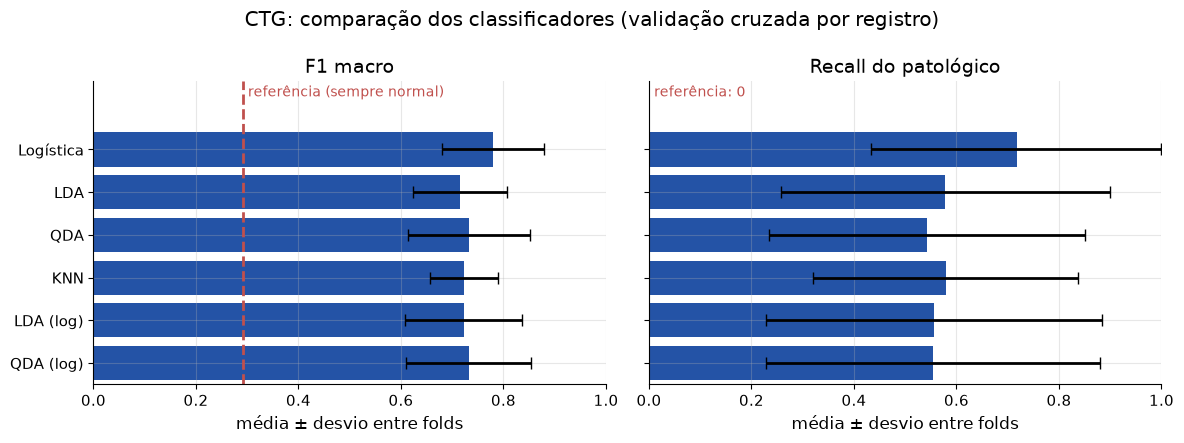

In [24]:
plotted = [row for row in table if row["model"] != BASELINE_LABEL]
y_pos = np.arange(len(plotted))
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5), sharey=True)
for ax, metric, title in [(axes[0], "f1_macro", "F1 macro"),
                          (axes[1], "pathological_recall", "Recall do patológico")]:
    mean = np.array([row[metric] for row in plotted])
    std = np.array([row[f"{metric}_std"] for row in plotted])
    # Barras de erro cortadas em [0, 1]: a métrica não sai desse intervalo.
    err = [mean - np.clip(mean - std, 0, 1), np.clip(mean + std, 0, 1) - mean]
    ax.barh(y_pos, mean, xerr=err, capsize=4, color="C0")
    ax.set_xlim(0, 1)
    ax.set_title(title)
    ax.set_xlabel("média ± desvio entre folds")
axes[0].axvline(baseline["f1_macro"], color="C1", ls="--")
axes[0].set_yticks(y_pos, [row["model"] for row in plotted])
axes[0].set_ylim(len(plotted) - 0.5, -1.6)  # de cima para baixo, com espaço para o rótulo
axes[0].text(baseline["f1_macro"] + 0.01, -1.5, "referência (sempre normal)", color="C1",
             va="top", fontsize=10)
axes[1].text(0.01, -1.5, "referência: 0", color="C1", va="top", fontsize=10)
fig.suptitle("CTG: comparação dos classificadores (validação cruzada por registro)")
fig.tight_layout()
save_figure(fig, "ctg_comparacao")
plt.show()

#### 8. Hiperparâmetros escolhidos

(salvos para as próximas etapas)

In [25]:
FIXED = {"logistic": {"model__learning_rate": 1.0, "model__max_iter": 5000}}

best = {}
for key, search in searches.items():
    uses_log = key in searches_log and (
        searches_log[key].best_score_ > search.best_score_ + 0.01)
    chosen = searches_log[key] if uses_log else search
    best[key] = {
        "fixed": FIXED.get(key, {}),
        "params": chosen.best_params_,
        "f1_macro_cv": float(chosen.best_score_),
        "uses_log1p": bool(uses_log),
    }
    print(f"{LABELS[key]:10s} {best[key]['params']}  F1 {chosen.best_score_:.3f}"
          f"{'  (com log1p)' if uses_log else ''}")

with open(TABLES / "ctg_hiperparametros.json", "w", encoding="utf-8") as f:
    json.dump({"seed": SEED, **best}, f, indent=2)

Logística  {'model__alpha': 10}  F1 0.780
LDA        {'model__reg_param': 1e-06}  F1 0.715
QDA        {'model__reg_param': 0.5}  F1 0.733
KNN        {'model__n_neighbors': 15}  F1 0.723


#### 9. Conclusão da comparação de classificadores na CTG

- A validação por registro muda a escolha. 

- Melhor modelo por F1 macro: logística com `alpha = 10` (0,780 ± 0,099).

- Recall do patológico: a logística tem o maior (0,718), mas o desvio entre folds é grande (± 0,28). O KNN é o que mais manda patológicos para "normal".

- Baseline: a classe majoritária acerta 77,7% dos exames, mas tem F1 macro 0,291 e recall patológico zero. Todos os modelos ganham dela, e é por isso que não reportamos só a acurácia.

#### 10. LOOCV × KFold

Comparar as estimativas de erro da LOOCV e do KFold(10) para LDA, QDA e logística.

##### 10.1 Modelos

Os três modelos são montados com os hiperparâmetros escolhidos na seção 4 e salvos na seção 8.

In [26]:
def pipeline_from_json(name, classifier):
    """Monta o Pipeline do modelo com os hiperparâmetros salvos na seção 8."""
    with open(TABLES / "ctg_hiperparametros.json", encoding="utf-8") as f:
        hp = json.load(f)[name]

    assert not hp["uses_log1p"], f"{name} usa log1p; o X precisa ser transformado"

    pipe = make_pipeline(classifier)
    pipe.set_params(**hp["fixed"], **hp["params"])
    return pipe


MODELS_T5 = {
    "logistic": pipeline_from_json("logistic", LogisticRegression()),
    "lda": pipeline_from_json("lda", LinearDiscriminantAnalysis()),
    "qda": pipeline_from_json("qda", QuadraticDiscriminantAnalysis()),
}

for name, pipe in MODELS_T5.items():
    print(f"{name:9s} {pipe.steps[-1][1]}")

logistic  LogisticRegression(alpha=10, fit_intercept=True, learning_rate=1.0, max_iter=5000, tol=1e-06)
lda       LinearDiscriminantAnalysis(priors=None, reg_param=1e-06)
qda       QuadraticDiscriminantAnalysis(priors=None, reg_param=0.5)


##### 10.2 Tempo de um ajuste

A LOOCV treina o modelo uma vez para cada exame do treino. Medimos um ajuste de cada modelo para estimar quanto ela vai demorar.

In [35]:
n_train = len(y_train)
for name, pipe in MODELS_T5.items():
    start = time.perf_counter()
    pipe.fit(X_train, y_train)
    elapsed = time.perf_counter() - start
    print(f"{LABELS[name]:10s} um ajuste: {elapsed:.3f} s   "
          f"LOOCV estimada ({n_train} ajustes): {elapsed * n_train / 60:.1f} min")

Logística  um ajuste: 0.473 s   LOOCV estimada (1755 ajustes): 13.8 min
LDA        um ajuste: 0.006 s   LOOCV estimada (1755 ajustes): 0.2 min
QDA        um ajuste: 0.004 s   LOOCV estimada (1755 ajustes): 0.1 min


##### 10.3 Validação cruzada com e sem cache

In [ ]:
def predict_cv(model, splitter):
    """Previsões fora da amostra e o tempo gasto para calculá-las."""
    start = time.perf_counter()
    pred = cross_val_predict(model, X_train, y_train, cv=splitter)
    elapsed = time.perf_counter() - start
    return pred, elapsed

def cached_predict_cv(name, method, model, splitter):
    """Como predict_cv, mas calcula uma vez e guarda em data/processed."""
    pred_path = PROCESSED / f"ctg_loo_{name}_{method}.npy"
    info_path = PROCESSED / f"ctg_loo_{name}_{method}.json"
    params = repr(model)

    if pred_path.exists() and info_path.exists():
        with open(info_path, encoding="utf-8") as f:
            info = json.load(f)
        pred = np.load(pred_path)
        if info["params"] == params and len(pred) == len(y_train):
            return pred, info["seconds"]
        print(f"{name} ({method}): o modelo ou os dados mudaram, recalculando")

    pred, elapsed = predict_cv(model, splitter)
    np.save(pred_path, pred)
    with open(info_path, "w", encoding="utf-8") as f:
        json.dump({"params": params, "seconds": elapsed}, f, indent=2)
    return pred, elapsed

def error_and_f1(pred):
    """Taxa de erro e F1 macro de previsões sobre todo o treino."""
    metrics = evaluate_classifier(y_train, pred)
    return 1 - metrics["accuracy"], metrics["f1_macro"]

def evaluate_cv(model, splitter):
    """Erro, F1 macro e tempo de uma validação cruzada."""
    pred, elapsed = predict_cv(model, splitter)
    error, f1 = error_and_f1(pred)
    return error, f1, elapsed

pred_loo, seconds = cached_predict_cv("logistic", "row", MODELS_T5["logistic"], LeaveOneOut())
error, f1 = error_and_f1(pred_loo)

##### 10.4 KFold(10) com 5 sementes e LOOCV

Cada KFold é repetido com 5 sementes, para medir quanto o resultado varia só pelo sorteio dos folds. A LOOCV não tem sorteio, então roda uma vez (desvio 0).

#### 11. Limiar para o patológico

Deixar passar um patológico é muito pior que um alarme falso. Em vez de
prever a classe mais provável, marcamos patológico sempre que a
probabilidade passa de um limiar t, escolhido no treino para garantir
recall de pelo menos 0,9.

##### 11.1 Modelo

In [33]:
logistic_pipe = pipeline_from_json("logistic", LogisticRegression())
print(logistic_pipe)

Pipeline(steps=[('scaler', StandardScaler(columns=None, with_mean=True, with_std=True)), ('model', LogisticRegression(alpha=10, fit_intercept=True, learning_rate=1.0, max_iter=5000, tol=1e-06))])


##### 11.2 Probabilidades fora da amostra

Cada exame do treino recebe probabilidades de um modelo que não o viu, usando a mesma validação por registro da seção 2. É com essas probabilidades que o limiar vai ser escolhido.

In [28]:
proba = cross_val_predict(logistic_pipe, X_train, y_train, cv=cv, method="predict_proba")

assert proba.shape == (len(y_train), 3)
assert np.allclose(proba.sum(axis=1), 1)

pred_argmax = np.argmax(proba, axis=1)
recall_argmax = np.mean(pred_argmax[y_train == PATHOLOGICAL] == PATHOLOGICAL)
print(f"proba: {proba.shape}")
print(f"recall do patológico sem limiar: {recall_argmax:.3f}")

proba: (1755, 3)
recall do patológico sem limiar: 0.735


##### 11.3 Recall e precisão × limiar

Para cada t da grade, calculamos o recall e a precisão do patológico. O limiar escolhido é o maior t com recall de pelo menos 0,9.

In [29]:
MIN_RECALL = 0.9

recall_curve, precision_curve = threshold_curve(proba, y_train, PATHOLOGICAL, THRESHOLDS)
t = choose_threshold(proba, y_train, PATHOLOGICAL, min_recall=MIN_RECALL)
i = np.flatnonzero(np.isclose(THRESHOLDS, t))[0]

print(f"limiar escolhido: t = {t:.2f}")
print(f"recall do patológico:   {recall_curve[i]:.3f} (sem limiar: {recall_argmax:.3f})")
print(f"precisão do patológico: {precision_curve[i]:.3f}")

limiar escolhido: t = 0.11
recall do patológico:   0.918 (sem limiar: 0.735)
precisão do patológico: 0.553


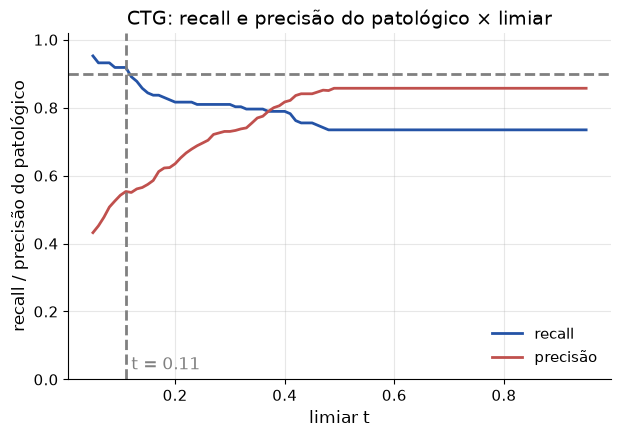

In [30]:
fig, ax = plt.subplots()
ax.plot(THRESHOLDS, recall_curve, label="recall")
ax.plot(THRESHOLDS, precision_curve, label="precisão")
ax.axvline(t, linestyle="--", color="gray")
ax.axhline(MIN_RECALL, linestyle="--", color="gray")
ax.text(t + 0.01, 0.03, f"t = {t:.2f}", color="gray")
ax.set_ylim(0, 1.02)
ax.set_xlabel("limiar t")
ax.set_ylabel("recall / precisão do patológico")
ax.set_title("CTG: recall e precisão do patológico × limiar")
ax.legend(loc="lower right")
save_figure(fig, "ctg_limiar")
plt.show()

A partir de certo t, o recall e a precisão ficam constantes. Isso acontece porque o limiar só acrescenta patológicos: os exames em que o patológico já é a classe mais provável continuam marcados com qualquer t. Quando t passa da probabilidade de todos os outros, só sobram esses, e a curva vira a do modelo sem limiar.

Com 3 classes, a mais provável tem probabilidade de pelo menos 1/3, e acima de 0,5 ela é sempre a mais provável. Por isso, a curva fica constante com certeza a partir de t = 0,5, e pode começar a ficar antes, entre 1/3 e 0,5.

##### 11.4 Com e sem limiar

Comparação, nas probabilidades fora da amostra do treino, entre prever a classe mais provável e prever com o limiar escolhido.

In [31]:
pred_t = predict_with_threshold(proba, np.unique(y_train), PATHOLOGICAL, t)

rows = []
for label, pred in [("sem limiar", pred_argmax), (f"limiar t = {t:.2f}", pred_t)]:
    metrics = evaluate_classifier(y_train, pred)
    rows.append({
        "model": label,
        "f1_macro": metrics["f1_macro"],
        "pathological_recall": metrics[f"recall_{PATHOLOGICAL}"],
        "pathological_precision": metrics[f"precision_{PATHOLOGICAL}"],
    })

print(f"{'':16s} {'F1 macro':>9s} {'recall pat.':>12s} {'precisão pat.':>14s}")
for row in rows:
    print(f"{row['model']:16s} {row['f1_macro']:9.3f} "
          f"{row['pathological_recall']:12.3f} {row['pathological_precision']:14.3f}")

rounded = [{k: round(v, 4) if isinstance(v, float) else v for k, v in row.items()}
           for row in rows]
save_table(rounded, "ctg_limiar")

                  F1 macro  recall pat.  precisão pat.
sem limiar           0.796        0.735          0.857
limiar t = 0.11      0.707        0.918          0.553


WindowsPath('C:/Users/Sistemas/Desktop/IMPA TECH/MachineLearning/statstech-analise/results/tables/ctg_limiar.csv')

Com o limiar t = 0,11, o recall do patológico sobe de 0,735 para 0,918: a cada 100 exames patológicos, o modelo passa a deixar escapar 8,2 em vez de 26,5. O custo é a precisão, que cai de 0,857 para 0,553: de cada 100 exames marcados como patológicos, cerca de 45 são alarmes falsos (antes eram 14). O F1 macro vai de 0,796 para 0,707.

Obs.: o F1 macro não é o critério aqui. Ele pesa as três classes igualmente e penaliza os alarmes falsos, mas para o patológico deixar passar um exame é muito mais grave que dar um alarme falso. Por isso trocamos um pouco de F1 macro por recall.

Obs.: o recall de 0,918 foi medido na validação do treino, com 147 patológicos. O teste tem bem menos (27), e cada exame perdido ali pesa quase 4 pontos no recall. Por isso, o recall no teste pode ficar um pouco abaixo de 0,9 por acaso, sem que nada tenha dado errado.

##### 11.5 Limiar salvo

(salvo para as próximas etapas)

In [32]:
threshold_info = {
    "seed": SEED,
    "model": "logistic",
    "positive": int(PATHOLOGICAL),
    "min_recall": float(MIN_RECALL),
    "threshold": float(t),
    "recall_cv": float(recall_curve[i]),
    "precision_cv": float(precision_curve[i]),
    "cv": "StratifiedGroupKFold(10)",
}

with open(TABLES / "ctg_limiar.json", "w", encoding="utf-8") as f:
    json.dump(threshold_info, f, indent=2)

print(json.dumps(threshold_info, indent=2))

{
  "seed": 72,
  "model": "logistic",
  "positive": 2,
  "min_recall": 0.9,
  "threshold": 0.11,
  "recall_cv": 0.9183673469387755,
  "precision_cv": 0.5532786885245902,
  "cv": "StratifiedGroupKFold(10)"
}


##### 11.6 Conclusão do limiar

- Limiar escolhido: t = 0,11, o maior da grade com recall do patológico de pelo menos 0,9 nas probabilidades fora da amostra da validação por registro.

- Com o limiar, o recall do patológico vai de 0,735 para 0,918, e a precisão de 0,857 para 0,553: a cada 100 patológicos, deixamos escapar 8 em vez de 26, ao custo de cerca de 45 alarmes falsos a cada 100 exames marcados.

- O F1 macro cai de 0,796 para 0,707. Ele não é o critério aqui, porque trata o alarme falso e o patológico perdido como erros do mesmo peso.

- Como t < 1/3, as duas regras de limiar (manter o patológico do argmax ou exigir p ≥ t) dão o mesmo resultado: se o patológico é a classe mais provável, sua probabilidade já é pelo menos 1/3 > t.

- O limiar garante recall de 0,9 na validação do treino. No teste, com cerca de 27 patológicos, o recall pode ficar um pouco abaixo disso. O T7 vai medir.

- Por que t = 0,11 e não perto de 0,5: o patológico é só 8,4% do treino, e a logística com `alpha = 10` é bem regularizada. As duas coisas puxam a probabilidade do patológico para baixo, então mesmo exames patológicos de verdade costumam receber probabilidades pequenas. O valor de t só faz sentido na escala dessas probabilidades. Por isso ele é escolhido nos dados, e não fixado em 0,5.